# Baseline: Reis & Ribeiro [17] — face-recognition similarity scores + threshold / likelihood-ratio decision (P2datasetFull)

**Paper:** P. M. G. I. Reis & R. O. Ribeiro, *A forensic evaluation method for DeepFake detection using DCNN-based facial similarity scores*, Forensic Science International 358 (2024) 111747. doi:10.1016/j.forsciint.2023.111747

**What the paper does**
1. Extracts faces from the questioned video and from reference material of the same person.
2. Computes similarity scores between every questioned face and every reference face with a DCNN trained for face recognition.
3. Keeps the **highest** score and compares it to a **threshold** → authentic or fake (reported HTER 0.020, AUC 0.994 on Celeb-DF v2).
4. Converts the highest score into a **likelihood ratio** with logistic regression (H1 = authentic, H2 = face-swapped), validated with a Tippett plot and Cllr.

**How this notebook adapts it to P2datasetFull**
- Reference material = all *real* images in `train` (the dataset has no identity labels, so the gallery is not identity-matched like in the paper).
- Questioned items = single images in `val1` / `test1` (the paper works per video).
- `val1` is used to pick the threshold and fit the LR model; `test1` is used only for evaluation.

⚠️ **Backbone:** the full text was not accessible when this was written, so the exact DCNN used by Reis & Ribeiro is **not confirmed**. This notebook uses InsightFace **ArcFace `buffalo_l`** (ResNet-50) as a stand-in. Check Section 3 of the paper and update the thesis text (and `BACKBONE_NOTE` below) to match.

**Before running:** Runtime → Change runtime type → T4 GPU → Save. Then Runtime → Run all. Cell 2 asks you to sign in to Google and adds the shared `ML-dataset` folder to your My Drive automatically.

In [1]:
# Cell 1: install packages (takes ~2-3 minutes; insightface compiles once)
!pip install -q insightface onnxruntime-gpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 17.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 255.6/255.6 MB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 60.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 38.1 MB/s eta 0:00:00


In [2]:
# Cell 2: connect the shared ML-dataset folder to YOUR Drive, mount it, and set configuration
# A Google sign-in popup appears: choose your account and click Allow (twice: once for auth, once for Drive).
import glob, os, time
from pathlib import Path
from google.colab import auth, drive
from googleapiclient.discovery import build

ML_DATASET_FOLDER_ID = "1hgPjQLaXEq1ZEjlUeEFdkWE-Y6Weyk_4"   # the group's ML-dataset folder

auth.authenticate_user()
svc = build("drive", "v3")
existing = svc.files().list(
    q="'root' in parents and trashed = false and mimeType = 'application/vnd.google-apps.shortcut'",
    fields="files(id,name,shortcutDetails)", pageSize=1000).execute().get("files", [])
if any(f.get("shortcutDetails", {}).get("targetId") == ML_DATASET_FOLDER_ID for f in existing):
    print("ML-dataset shortcut already in My Drive")
else:
    svc.files().create(body={
        "name": "ML-dataset",
        "mimeType": "application/vnd.google-apps.shortcut",
        "parents": ["root"],
        "shortcutDetails": {"targetId": ML_DATASET_FOLDER_ID},
    }, fields="id").execute()
    print("Added ML-dataset shortcut to My Drive")

drive.mount("/content/drive", force_remount=True)

# Find the folder through the shortcut (new shortcuts can take a few seconds to appear)
ROOT = None
for _ in range(30):
    for c in [*glob.glob(f"/content/drive/.shortcut-targets-by-id/{ML_DATASET_FOLDER_ID}/*"),
              "/content/drive/MyDrive/ML-dataset"]:
        if (Path(c) / "P2datasetFull").is_dir():
            ROOT = Path(c); break
    if ROOT: break
    time.sleep(2)
if ROOT is None:
    raise FileNotFoundError("ML-dataset not visible yet. Runtime → Restart session, then run this cell again.")

DATASET_DIR = ROOT / "P2datasetFull"
SPLITS      = ["train", "val1", "test1"]
CLASS_MAP   = {"1": "real", "2": "fake"}          # same mapping as the CNN-Transformer notebook
LOCAL_ROOT  = Path("/content/p2_reis")            # fast local copy
RESULTS_DIR = ROOT / "P2_results" / "reis_ribeiro_baseline"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

MAX_PER_CLASS = None     # e.g. 300 for a quick test run; None = use every image
SEED          = 42
VALID_EXT     = {".jpg", ".jpeg", ".png", ".bmp"}
BACKBONE_NOTE = "InsightFace ArcFace buffalo_l (ResNet-50) - stand-in, confirm against the paper"

print("Dataset:", DATASET_DIR)
print("Results:", RESULTS_DIR)

Added ML-dataset shortcut to My Drive
Mounted at /content/drive
Dataset: /content/drive/.shortcut-targets-by-id/1hgPjQLaXEq1ZEjlUeEFdkWE-Y6Weyk_4/ML-dataset/P2datasetFull
Results: /content/drive/.shortcut-targets-by-id/1hgPjQLaXEq1ZEjlUeEFdkWE-Y6Weyk_4/ML-dataset/P2_results/reis_ribeiro_baseline


In [3]:
# Cell 3: copy images to local disk (much faster to read than Drive)
import random, shutil
from concurrent.futures import ThreadPoolExecutor

random.seed(SEED)
file_lists = {}

def copy_one(task):
    src, dst = task
    if not dst.exists():
        shutil.copy2(src, dst)
    return dst

for split in SPLITS:
    for folder, label in CLASS_MAP.items():
        src_dir = DATASET_DIR / split / folder
        if not src_dir.is_dir():
            raise FileNotFoundError(f"Missing folder {src_dir}")
        files = sorted(f for f in src_dir.iterdir() if f.suffix.lower() in VALID_EXT)
        if MAX_PER_CLASS:
            files = sorted(random.sample(files, min(MAX_PER_CLASS, len(files))))
        dst_dir = LOCAL_ROOT / split / label
        dst_dir.mkdir(parents=True, exist_ok=True)
        with ThreadPoolExecutor(max_workers=16) as pool:
            file_lists[(split, label)] = list(pool.map(copy_one, [(f, dst_dir / f.name) for f in files]))
        print(f"{split:6s} {label:5s} (folder {folder}): {len(files)} images")

train  real  (folder 1): 3207 images
train  fake  (folder 2): 3050 images
val1   real  (folder 1): 3150 images
val1   fake  (folder 2): 3071 images
test1  real  (folder 1): 3171 images
test1  fake  (folder 2): 3075 images


In [4]:
# Cell 4: load the face-recognition DCNN (detector + ArcFace embedding model)
import cv2
import numpy as np
import onnxruntime as ort
from insightface.app import FaceAnalysis

print("ONNX Runtime providers:", ort.get_available_providers())  # should include CUDAExecutionProvider

app = FaceAnalysis(name="buffalo_l",
                   providers=["CUDAExecutionProvider", "CPUExecutionProvider"],
                   allowed_modules=["detection", "recognition"])
app.prepare(ctx_id=0, det_size=(640, 640))
rec_model = app.models["recognition"]
print("Model ready:", BACKBONE_NOTE)

ONNX Runtime providers: ['AzureExecutionProvider', 'CPUExecutionProvider']
download_path: /root/.insightface/models/buffalo_l


100%|██████████| 281857/281857 [00:03<00:00, 79813.96KB/s]
/usr/local/lib/python3.13/dist-packages/onnxruntime/capi/onnxruntime_inference_collection.py:197: UserWarning: Specified provider 'CUDAExecutionProvider' is not in available provider names.Available providers: 'AzureExecutionProvider, CPUExecutionProvider'
  warnings.warn(


Model ready: InsightFace ArcFace buffalo_l (ResNet-50) - stand-in, confirm against the paper


In [5]:
# Cell 5: embedding function
# Images in P2datasetFull may already be tight face crops, which the detector sometimes misses.
# Order of attempts: detect on the image -> detect on a padded image -> resize whole image to 112x112.
def l2norm(v):
    return v / (np.linalg.norm(v) + 1e-12)

def embed_image(path):
    img = cv2.imread(str(path))              # BGR, as insightface expects
    if img is None:
        return None, "unreadable"
    faces, mode = app.get(img), "detected"
    if not faces:
        h, w = img.shape[:2]
        pad = int(0.5 * max(h, w))
        padded = cv2.copyMakeBorder(img, pad, pad, pad, pad, cv2.BORDER_CONSTANT, value=0)
        faces, mode = app.get(padded), "detected_padded"
    if faces:
        face = max(faces, key=lambda f: (f.bbox[2] - f.bbox[0]) * (f.bbox[3] - f.bbox[1]))
        return face.normed_embedding.astype(np.float32), mode
    emb = rec_model.get_feat(cv2.resize(img, (112, 112))).flatten().astype(np.float32)
    return l2norm(emb), "no_face_resized"

emb, mode = embed_image(file_lists[("train", "real")][0])
print("Test embedding:", emb.shape, mode)

Test embedding: (512,) no_face_resized


In [6]:
# Cell 6: extract embeddings for every split (cached to Drive, so reruns are fast)
from collections import Counter
from tqdm.auto import tqdm

LABEL_ID = {"real": 0, "fake": 1}   # 1 = fake (positive class for detection metrics)

def extract_split(split):
    cache = RESULTS_DIR / f"embeddings_{split}_max{MAX_PER_CLASS}.npz"
    if cache.exists():
        d = np.load(cache, allow_pickle=True)
        print(f"{split}: loaded cache ({len(d['label'])} images)")
        return {k: d[k] for k in d.files}
    embs, labels, paths, modes = [], [], [], []
    for label in ["real", "fake"]:
        for p in tqdm(file_lists[(split, label)], desc=f"{split}/{label}"):
            e, m = embed_image(p)
            if e is None:
                continue
            embs.append(e); labels.append(LABEL_ID[label]); paths.append(p.name); modes.append(m)
    d = {"emb": np.stack(embs), "label": np.array(labels),
         "path": np.array(paths), "mode": np.array(modes)}
    np.savez(cache, **d)
    print(f"{split}: {len(labels)} embeddings, modes = {dict(Counter(modes))}")
    return d

data = {split: extract_split(split) for split in SPLITS}

train/real:   0%|          | 0/3207 [00:00<?, ?it/s]

train/fake:   0%|          | 0/3050 [00:00<?, ?it/s]

train: 6257 embeddings, modes = {'no_face_resized': 2497, 'detected': 3429, 'detected_padded': 331}


val1/real:   0%|          | 0/3150 [00:00<?, ?it/s]

val1/fake:   0%|          | 0/3071 [00:00<?, ?it/s]

val1: 6221 embeddings, modes = {'no_face_resized': 2292, 'detected': 3647, 'detected_padded': 282}


test1/real:   0%|          | 0/3171 [00:00<?, ?it/s]

test1/fake:   0%|          | 0/3075 [00:00<?, ?it/s]

test1: 6246 embeddings, modes = {'no_face_resized': 2436, 'detected_padded': 343, 'detected': 3467}


In [7]:
# Cell 7: similarity scores — highest cosine similarity to the reference gallery (as in the paper)
gallery = data["train"]["emb"][data["train"]["label"] == 0]     # real training faces = reference material
print("Reference gallery:", gallery.shape)

def highest_score(queries, gal, chunk=2048):
    out = []
    for i in range(0, len(queries), chunk):
        out.append((queries[i:i + chunk] @ gal.T).max(axis=1))   # embeddings are L2-normalised -> cosine
    return np.concatenate(out)

s_val,  y_val  = highest_score(data["val1"]["emb"],  gallery), data["val1"]["label"]
s_test, y_test = highest_score(data["test1"]["emb"], gallery), data["test1"]["label"]

# Leakage check: near-identical matches usually mean frames from the same video ended up in train and test.
for name, s, y in [("val1", s_val, y_val), ("test1", s_test, y_test)]:
    print(f"{name}: mean score real={s[y==0].mean():.3f}  fake={s[y==1].mean():.3f}  | "
          f"share > 0.95: real={np.mean(s[y==0] > 0.95):.1%}  fake={np.mean(s[y==1] > 0.95):.1%}")

Reference gallery: (3207, 512)
val1: mean score real=0.537  fake=0.390  | share > 0.95: real=0.7%  fake=0.0%
test1: mean score real=0.536  fake=0.402  | share > 0.95: real=0.3%  fake=0.0%


In [8]:
# Cell 8: threshold decision (threshold chosen at the EER point on val1, applied unchanged to test1)
from sklearn.metrics import (roc_curve, roc_auc_score, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix)

fpr, tpr, thr = roc_curve(y_val, -s_val)       # lower similarity = more likely fake
fnr = 1 - tpr
i = np.nanargmin(np.abs(fnr - fpr))
threshold = -thr[i]                              # predict FAKE when score < threshold
print(f"val1 EER = {(fpr[i] + fnr[i]) / 2:.4f}  ->  similarity threshold = {threshold:.4f}")

pred_test = (s_test < threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred_test, labels=[0, 1]).ravel()
far  = fn / (fn + tp)      # fake accepted as authentic
frr  = fp / (fp + tn)      # authentic rejected as fake
metrics = {
    "accuracy":  accuracy_score(y_test, pred_test),
    "precision": precision_score(y_test, pred_test, zero_division=0),
    "recall":    recall_score(y_test, pred_test, zero_division=0),
    "f1":        f1_score(y_test, pred_test, zero_division=0),
    "roc_auc":   roc_auc_score(y_test, -s_test),
    "FAR": far, "FRR": frr, "HTER": (far + frr) / 2,
    "threshold": float(threshold),
}
print("\ntest1 results (positive class = fake):")
for k, v in metrics.items():
    print(f"  {k:9s} {v:.4f}")
print("Confusion matrix [[TN FP],[FN TP]]:", [[tn, fp], [fn, tp]])

val1 EER = 0.3577  ->  similarity threshold = 0.2836

test1 results (positive class = fake):
  accuracy  0.6305
  precision 0.6238
  recall    0.6283
  f1        0.6261
  roc_auc   0.6300
  FAR       0.3717
  FRR       0.3674
  HTER      0.3695
  threshold 0.2836
Confusion matrix [[TN FP],[FN TP]]: [[np.int64(2006), np.int64(1165)], [np.int64(1143), np.int64(1932)]]


In [9]:
# Cell 9: likelihood ratio (logistic regression on the highest score, fitted on val1)
# H1 (numerator) = authentic, H2 (denominator) = fake — same orientation as the paper.
from sklearn.linear_model import LogisticRegression

y_val_auth, y_test_auth = 1 - y_val, 1 - y_test
calib = LogisticRegression().fit(s_val.reshape(-1, 1), y_val_auth)
prior_log_odds = np.log(y_val_auth.mean() / (1 - y_val_auth.mean()))

def log10_lr(scores):
    return (calib.decision_function(scores.reshape(-1, 1)) - prior_log_odds) / np.log(10)

def cllr(llr10, y_auth):
    ln = llr10 * np.log(10)
    h1 = np.logaddexp(0, -ln[y_auth == 1]).mean() / np.log(2)
    h2 = np.logaddexp(0,  ln[y_auth == 0]).mean() / np.log(2)
    return 0.5 * (h1 + h2)

llr_test = log10_lr(s_test)
metrics["Cllr"] = cllr(llr_test, y_test_auth)
metrics["misleading_H1"] = float(np.mean(llr_test[y_test_auth == 1] < 0))   # authentic but LR < 1
metrics["misleading_H2"] = float(np.mean(llr_test[y_test_auth == 0] > 0))   # fake but LR > 1

# Human-in-the-loop hook: weak evidence (|log10 LR| < 1, i.e. LR between 0.1 and 10) goes to a reviewer.
review = np.abs(llr_test) < 1
metrics["sent_to_review"] = float(review.mean())
metrics["accuracy_auto_decided"] = float(np.mean((llr_test[~review] < 0) == (y_test[~review] == 1)))

for k in ["Cllr", "misleading_H1", "misleading_H2", "sent_to_review", "accuracy_auto_decided"]:
    print(f"{k:22s} {metrics[k]:.4f}")

Cllr                   0.9592
misleading_H1          0.4642
misleading_H2          0.3008
sent_to_review         1.0000
accuracy_auto_decided  nan


/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:147: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


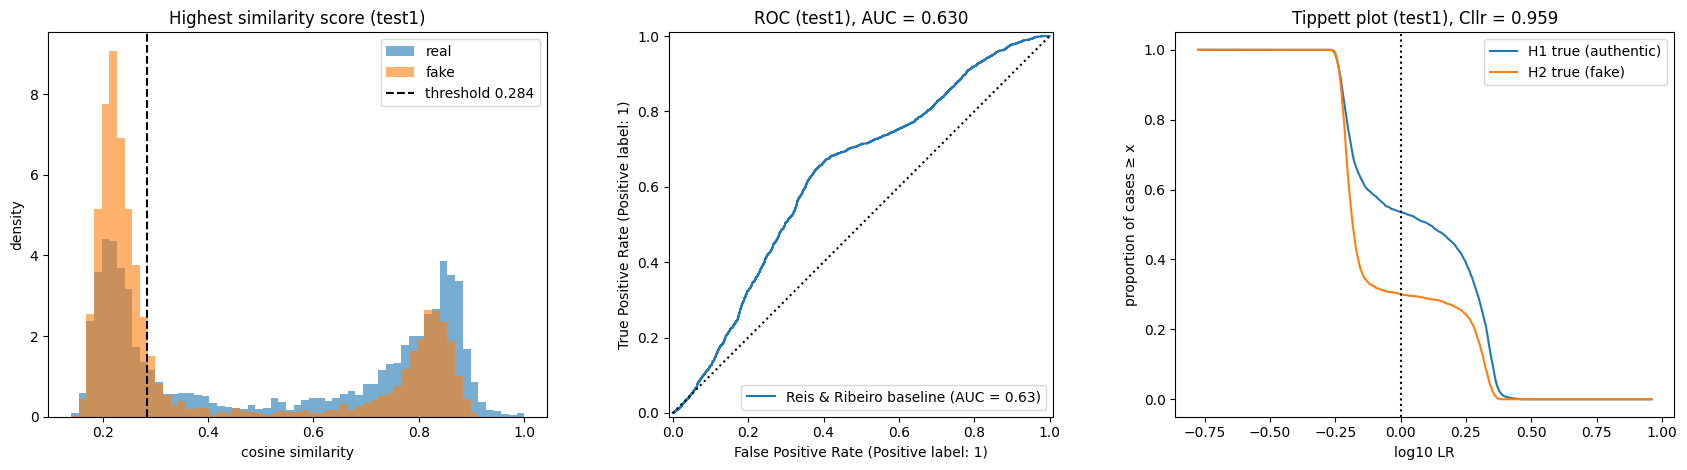

In [10]:
# Cell 10: plots — score distributions, ROC, Tippett
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))

bins = np.linspace(min(s_test.min(), s_val.min()), 1, 60)
ax[0].hist(s_test[y_test == 0], bins, alpha=.6, label="real", density=True)
ax[0].hist(s_test[y_test == 1], bins, alpha=.6, label="fake", density=True)
ax[0].axvline(threshold, color="k", ls="--", label=f"threshold {threshold:.3f}")
ax[0].set(title="Highest similarity score (test1)", xlabel="cosine similarity", ylabel="density")
ax[0].legend()

RocCurveDisplay.from_predictions(y_test, -s_test, ax=ax[1], name="Reis & Ribeiro baseline")
ax[1].plot([0, 1], [0, 1], "k:")
ax[1].set_title(f"ROC (test1), AUC = {metrics['roc_auc']:.3f}")

x = np.linspace(llr_test.min() - .5, llr_test.max() + .5, 400)
ax[2].plot(x, [(llr_test[y_test_auth == 1] >= v).mean() for v in x], label="H1 true (authentic)")
ax[2].plot(x, [(llr_test[y_test_auth == 0] >= v).mean() for v in x], label="H2 true (fake)")
ax[2].axvline(0, color="k", ls=":")
ax[2].set(title=f"Tippett plot (test1), Cllr = {metrics['Cllr']:.3f}",
          xlabel="log10 LR", ylabel="proportion of cases ≥ x")
ax[2].legend()

plt.tight_layout()
plt.savefig(RESULTS_DIR / "reis_ribeiro_baseline_plots.png", dpi=150)
plt.show()

In [11]:
# Cell 11: save results (summary JSON + per-image CSV) to Drive
import json
import pandas as pd

summary = {
    "method": "Reis & Ribeiro [17] - face-recognition similarity score + threshold / LR",
    "backbone": BACKBONE_NOTE,
    "reference_gallery": "real images from train split (not identity-matched)",
    "threshold_and_LR_fitted_on": "val1",
    "evaluated_on": "test1",
    "n_test": int(len(y_test)),
    "metrics": {k: float(v) for k, v in metrics.items()},
}
with open(RESULTS_DIR / "reis_ribeiro_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

pd.DataFrame({
    "file": data["test1"]["path"],
    "true_label": np.where(y_test == 1, "fake", "real"),
    "face_mode": data["test1"]["mode"],
    "highest_score": s_test,
    "pred_threshold": np.where(pred_test == 1, "fake", "real"),
    "log10_LR": llr_test,
    "needs_human_review": review,
}).to_csv(RESULTS_DIR / "reis_ribeiro_test1_scores.csv", index=False)

print(json.dumps(summary, indent=2))
print("\nSaved to", RESULTS_DIR)

{
  "method": "Reis & Ribeiro [17] - face-recognition similarity score + threshold / LR",
  "backbone": "InsightFace ArcFace buffalo_l (ResNet-50) - stand-in, confirm against the paper",
  "reference_gallery": "real images from train split (not identity-matched)",
  "threshold_and_LR_fitted_on": "val1",
  "evaluated_on": "test1",
  "n_test": 6246,
  "metrics": {
    "accuracy": 0.6304835094460455,
    "precision": 0.6238295124313852,
    "recall": 0.6282926829268293,
    "f1": 0.626053143227479,
    "roc_auc": 0.6299622852425308,
    "FAR": 0.37170731707317073,
    "FRR": 0.3673919899085462,
    "HTER": 0.36954965349085844,
    "threshold": 0.2835935354232788,
    "Cllr": 0.9591714366034718,
    "misleading_H1": 0.4642068748029013,
    "misleading_H2": 0.3008130081300813,
    "sent_to_review": 1.0,
    "accuracy_auto_decided": NaN
  }
}

Saved to /content/drive/.shortcut-targets-by-id/1hgPjQLaXEq1ZEjlUeEFdkWE-Y6Weyk_4/ML-dataset/P2_results/reis_ribeiro_baseline
